# 01 · Exploratory Data Analysis: Wildfire → Evacuation-Zone Risk

**Purpose:** understand the WiDS 2026 wildfire data before modelling: data quality, the target, feature distributions and the relationships that will shape preprocessing and model choice.

**Inputs:** `data/raw/train.csv` (labelled, 221 fires), `data/raw/test.csv` (unlabelled, 95 fires), `data/raw/metaData.csv` (column dictionary).

**Outputs:** figures in `reports/figures/01_*.png`, a cleaned copy in `data/processed/train_clean.csv`, and the *Key Findings* at the end of the notebook.

**Problem framing (competition):** this is **right-censored survival analysis**. `time_to_hit_hours` runs from t0+5h until the fire comes within 5 km of an evacuation-zone centroid (`event = 1`). If no hit is observed within the 72 h window, `event = 0` and the time is the last observed time (≤ 72 h). For each fire we predict **P(hit by 12 / 24 / 48 / 72 h)**, using one binary classifier per horizon, with risk % = `predict_proba × 100`.

Submissions are scored with **Hybrid = 0.3 × C-index + 0.7 × (1 − Weighted Brier)**, where Weighted Brier = 0.3·B@24h + 0.4·B@48h + 0.3·B@72h. Each B@H is censor-aware: a fire censored before H is excluded at H.

## Setup
Paths come from `pathlib`, relative to the project root, and `DATA_DIR` is the only data-location setting.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

from src.data import (load_raw, load_metadata, validate, clean, feature_columns,
                      censor_aware_labels, horizon_labels, HORIZONS, ID_COL, TIME_COL, EVENT_COL)
from src.features import add_engineered_features

DATA_DIR = ROOT / "data" / "raw"          # <- the only data location setting
FIG_DIR = ROOT / "reports" / "figures"
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True); PROC_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
C_NEG, C_POS = "#4C78A8", "#E45756"   # colour for 'never hit' vs 'hit'

def save(fig, name):
    """Save a figure to reports/figures as PNG."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

pd.set_option("display.width", 200, "display.max_columns", 50)

## 1. Load data & dataset overview
We load all three files and build a per-column overview table (dtype, missing values, unique counts, range) to check the data quality before any analysis.

In [2]:
train_raw, test_raw = load_raw(DATA_DIR)
meta = load_metadata(DATA_DIR)
print("train:", train_raw.shape, "| test:", test_raw.shape, "| metadata rows:", meta.shape[0])
print("train issues:", validate(train_raw) or "none")
print("test issues: ", validate(test_raw, require_targets=False) or "none")
print("event_id overlap train/test:", len(set(train_raw[ID_COL]) & set(test_raw[ID_COL])))

train: (221, 37) | test: (95, 35) | metadata rows: 37
train issues: none
test issues:  none
event_id overlap train/test: 0


In [3]:
overview = pd.DataFrame({
    "dtype": train_raw.dtypes.astype(str),
    "missing": train_raw.isna().sum(),
    "n_unique": train_raw.nunique(),
    "min": train_raw.min(numeric_only=True),
    "max": train_raw.max(numeric_only=True),
}).join(meta.set_index("column")[["category"]])
overview

,dtype,missing,n_unique,min,max,category
event_id,int64,0,221,1.089246e+07,9.933973e+07,identifier
num_perimeters_0_5h,int64,0,12,1.000000e+00,1.700000e+01,temporal_coverage
dt_first_last_0_5h,float64,0,62,0.000000e+00,4.994457e+00,temporal_coverage
low_temporal_resolution_0_5h,int64,0,2,0.000000e+00,1.000000e+00,temporal_coverage
area_first_ha,float64,0,221,3.752484e-02,1.194239e+04,growth
area_growth_abs_0_5h,float64,0,26,-2.156175e-05,2.508041e+03,growth
area_growth_rel_0_5h,float64,0,26,-1.437844e-07,1.788970e+01,growth
area_growth_rate_ha_per_h,float64,0,26,-5.292846e-06,5.204430e+02,growth
log1p_area_first,float64,0,221,3.683791e-02,9.387933e+00,growth
log1p_growth,float64,0,25,0.000000e+00,7.827656e+00,growth


Every column is numeric with **no missing values and no duplicates**. Many of the growth and kinematic columns have very few unique values, because most fires have only one perimeter in the first 5 h (see below).

In [4]:
train = clean(train_raw)
labels = censor_aware_labels(train[TIME_COL], train[EVENT_COL])   # competition labels: 1 / 0 / NaN (excluded)
train = pd.concat([train, labels], axis=1)
train["early_hit"] = ((train[EVENT_COL] == 1) & (train[TIME_COL] <= 12)).astype(int)   # helper for EDA only
FEATURES = feature_columns(train_raw)
train.drop(columns="early_hit").to_csv(PROC_DIR / "train_clean.csv", index=False)
print(len(FEATURES), "raw features; censor-aware labels added:", list(labels.columns))

34 raw features; censor-aware labels added: ['hit_12h', 'hit_24h', 'hit_48h', 'hit_72h']


## 2. Missing values
A bar chart of missing values per column. Even when there are none, the chart documents that check.

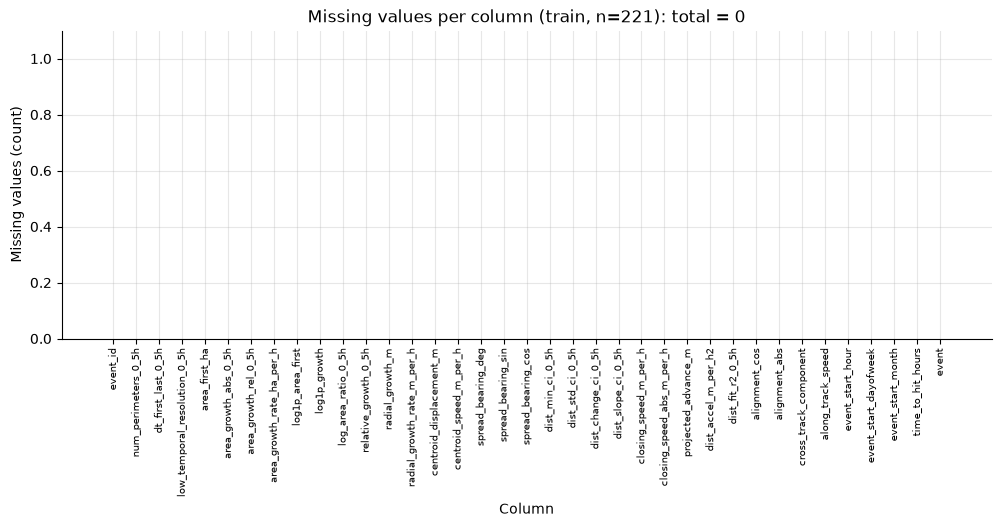

In [5]:
miss = train_raw.isna().sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(miss)), miss.values, color=C_NEG)
ax.set_xticks(range(len(miss)), miss.index, rotation=90, fontsize=7)
ax.set_ylim(0, max(1, miss.max()) * 1.1)
ax.set_title(f"Missing values per column (train, n={len(train_raw)}): total = {miss.sum()}")
ax.set_xlabel("Column"); ax.set_ylabel("Missing values (count)")
save(fig, "01_missing_values"); plt.show()

There are no missing values in any column. We still keep a `SimpleImputer` in the pipeline so that new data with gaps can be scored safely.

## 3. Target distribution
The raw target is survival-style (`time_to_hit_hours`, `event`). We look at (a) the censor-aware label counts per horizon, which follow the competition rule (hit by H → 1, censored after H → 0, censored at or before H → excluded), and (b) when hits and censoring happen.

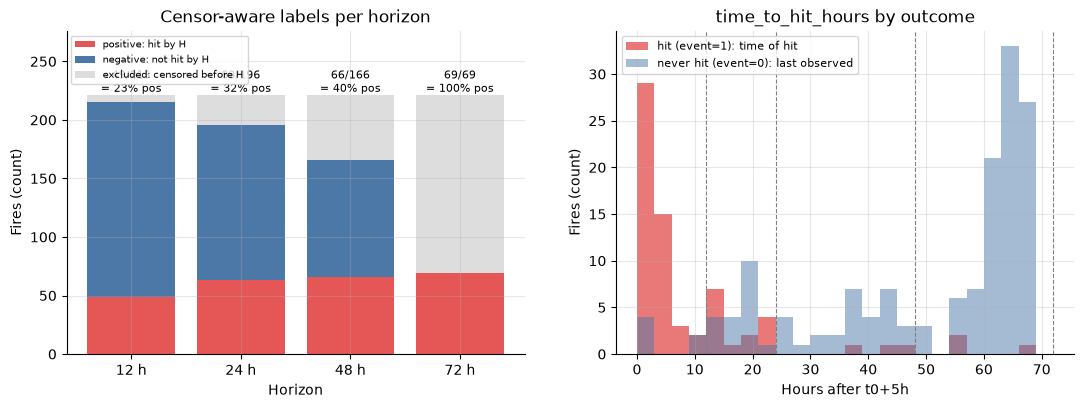

count    69.00
mean      9.97
std      14.53
min       0.00
25%       0.89
50%       3.53
75%      14.32
max      66.92
Name: time_to_hit_hours, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
pos, neg, exc = (labels == 1).sum(), (labels == 0).sum(), labels.isna().sum()
x = [f"{h} h" for h in HORIZONS]
axes[0].bar(x, pos, color=C_POS, label="positive: hit by H")
axes[0].bar(x, neg, bottom=pos, color=C_NEG, label="negative: not hit by H")
axes[0].bar(x, exc, bottom=pos + neg, color="#DDDDDD", label="excluded: censored before H")
for i, h in enumerate(HORIZONS):
    axes[0].text(i, len(labels) + 3, f"{pos.iloc[i]}/{pos.iloc[i] + neg.iloc[i]}\n= {pos.iloc[i] / (pos.iloc[i] + neg.iloc[i]) * 100:.0f}% pos", ha="center", fontsize=8)
axes[0].set_ylim(0, len(labels) * 1.25); axes[0].set_title("Censor-aware labels per horizon")
axes[0].set_xlabel("Horizon"); axes[0].set_ylabel("Fires (count)"); axes[0].legend(fontsize=7, loc="upper left")

bins = np.arange(0, 74, 3)
axes[1].hist(train.loc[train[EVENT_COL]==1, TIME_COL], bins=bins, color=C_POS, alpha=.8, label="hit (event=1): time of hit")
axes[1].hist(train.loc[train[EVENT_COL]==0, TIME_COL], bins=bins, color=C_NEG, alpha=.5, label="never hit (event=0): last observed")
for h in HORIZONS: axes[1].axvline(h, color="grey", ls="--", lw=.8)
axes[1].set_title("time_to_hit_hours by outcome"); axes[1].set_xlabel("Hours after t0+5h"); axes[1].set_ylabel("Fires (count)")
axes[1].legend(fontsize=8)
save(fig, "01_target_distribution"); plt.show()
print(train.loc[train[EVENT_COL]==1, TIME_COL].describe().round(2))

- **Only 31% of fires hit** (69/221). Most hits happen **early**: the median time to hit is about 3.5 h, and 49 of the 69 come within 12 h.
- **Censored fires were last observed between 0.4 h and 67 h, never at 72 h.** The censor-aware rule therefore excludes more of them as H grows: 6 at 12 h, 25 at 24 h, 55 at 48 h and **all 152 at 72 h**.
- **At 72 h every evaluable fire is a hit,** so Brier@72h only checks that fires which do hit get a high probability. Brier@48h (the most heavily weighted term) still has 100 negatives and 66 positives.
- Splits will be stratified on censored / late hit / early hit.

## 4. Feature distributions
Histograms of all 34 numeric features show their shape, skew and zero-inflation.

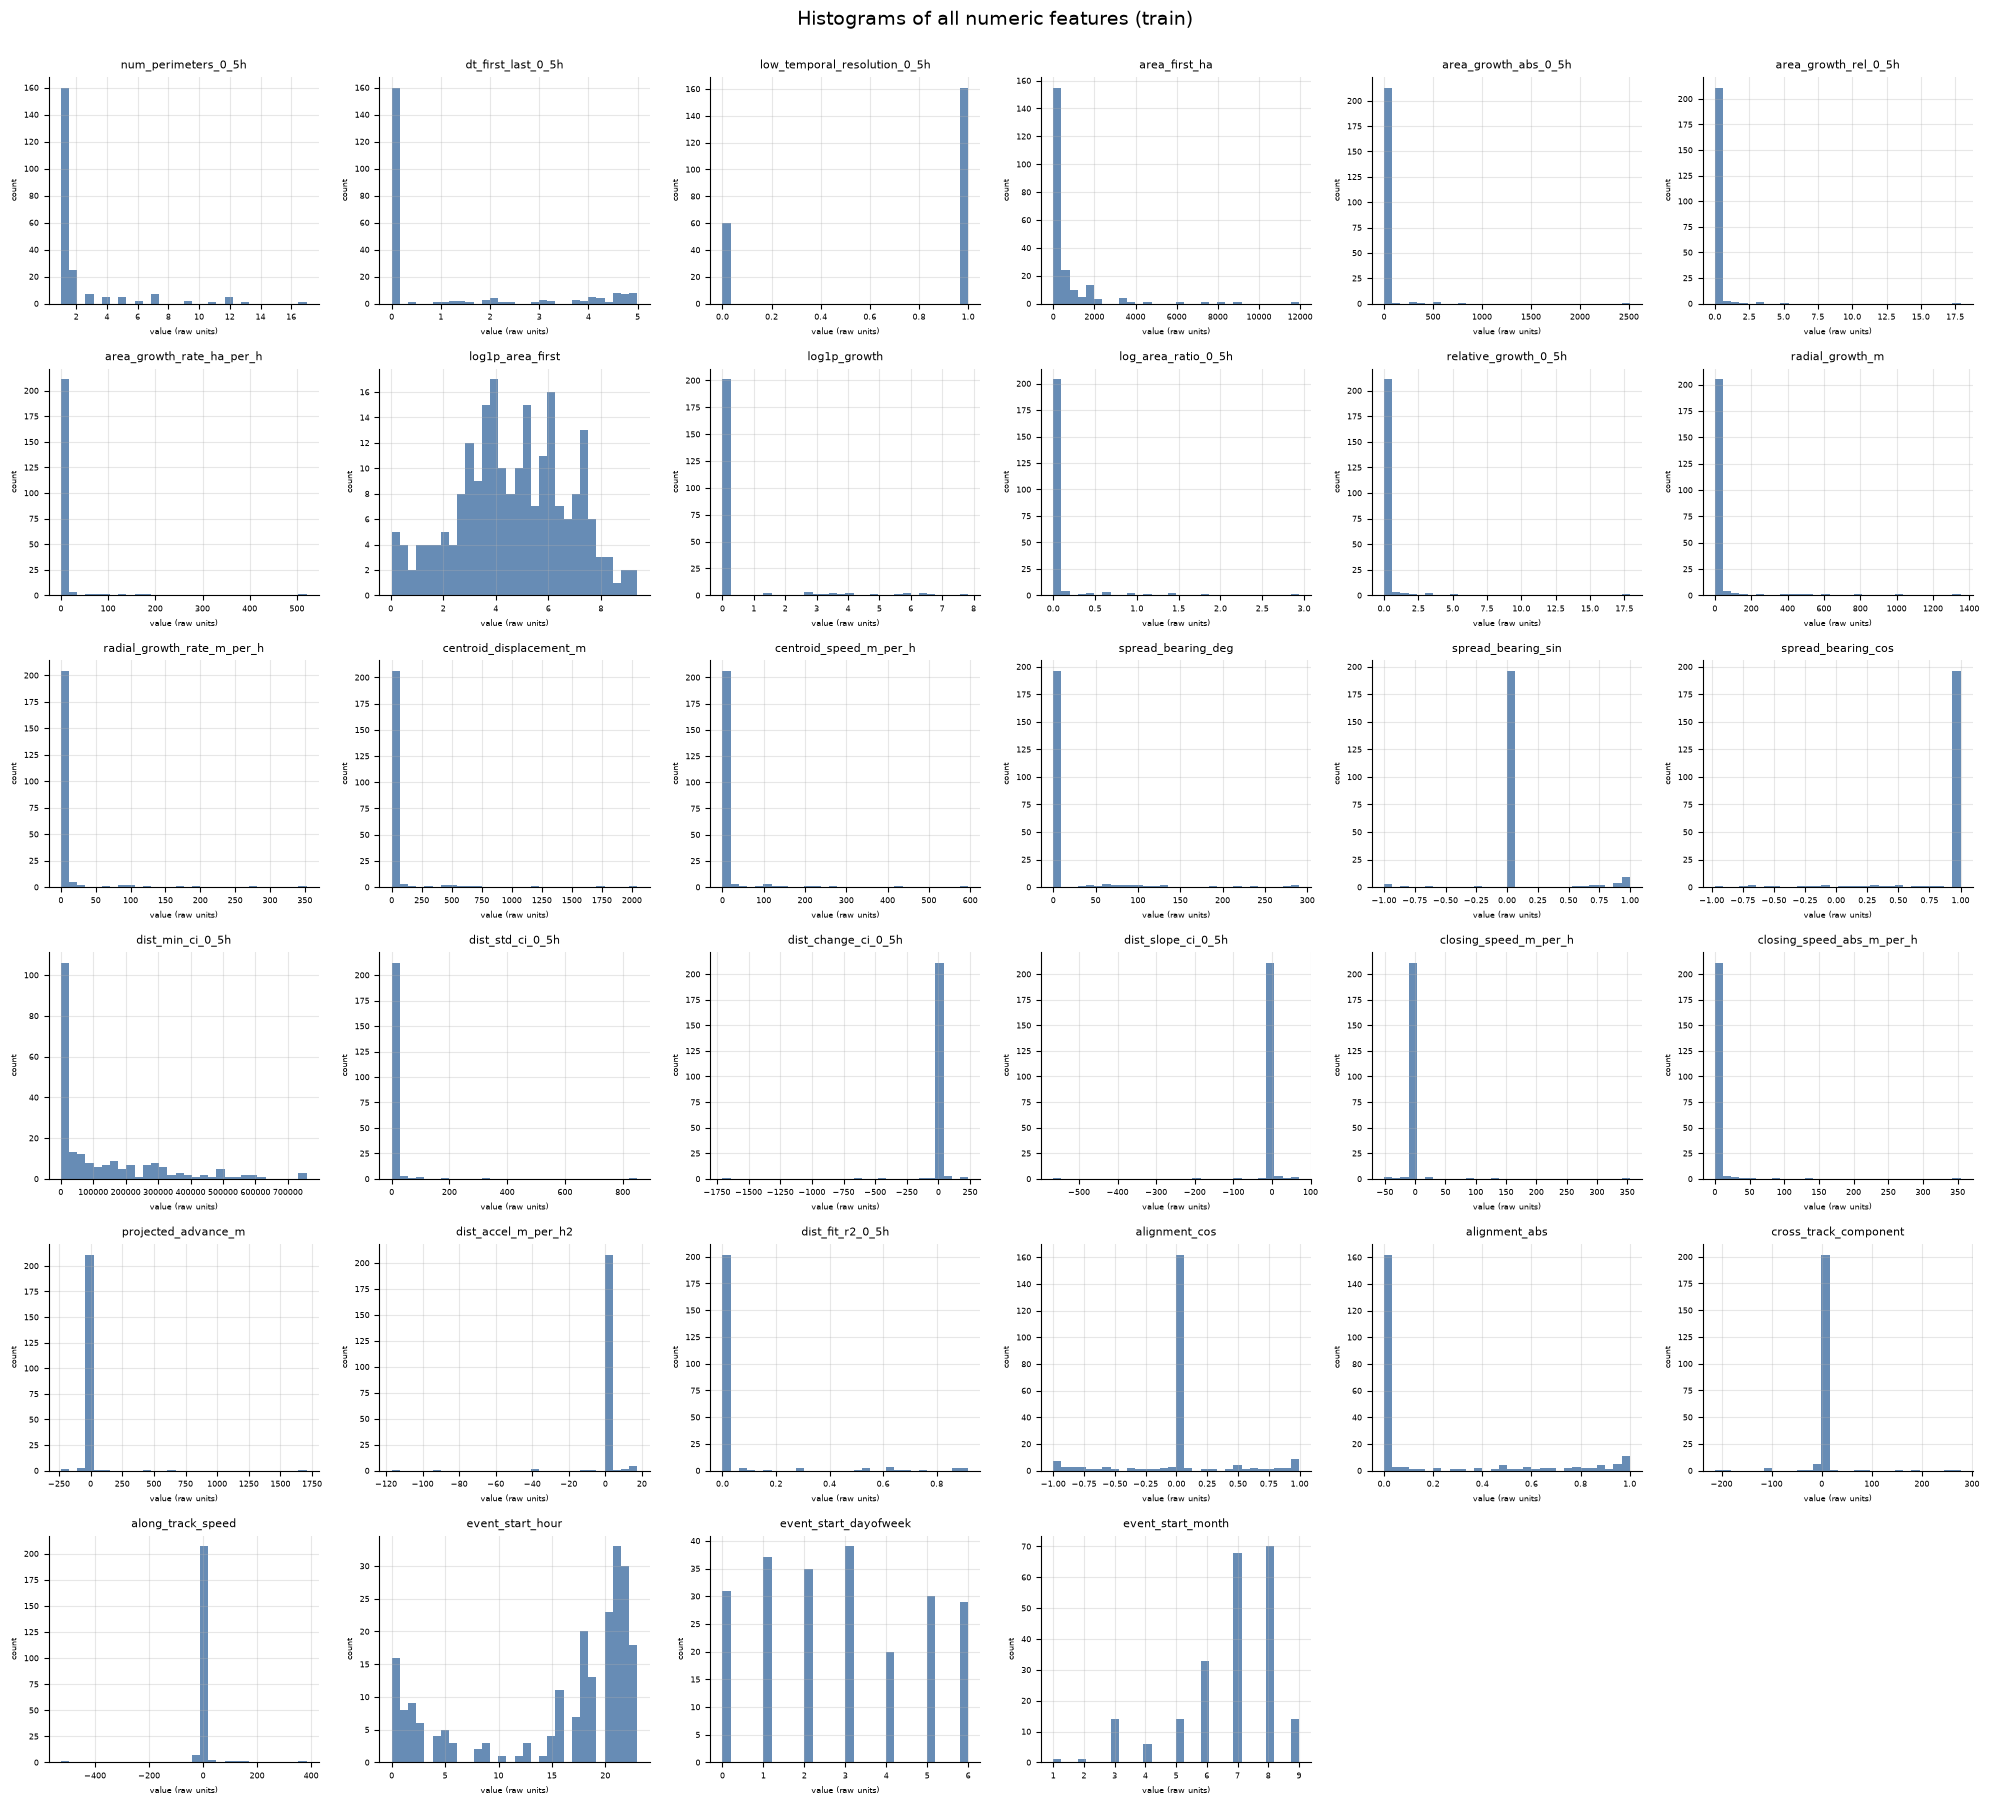

Share of zeros (top 10):
 closing_speed_abs_m_per_h    0.92
closing_speed_m_per_h        0.92
projected_advance_m          0.92
dist_change_ci_0_5h          0.92
dist_fit_r2_0_5h             0.91
dist_std_ci_0_5h             0.91
log1p_growth                 0.89
spread_bearing_sin           0.89
centroid_displacement_m      0.89
area_growth_rel_0_5h         0.89

low_temporal_resolution share: train 0.73 | test 0.78


In [7]:
n = len(FEATURES); ncols = 6; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3 * nrows))
for ax, col in zip(axes.flat, FEATURES):
    ax.hist(train[col], bins=30, color=C_NEG, alpha=.85)
    ax.set_title(col, fontsize=8); ax.tick_params(labelsize=6)
    ax.set_xlabel("value (raw units)", fontsize=6); ax.set_ylabel("count", fontsize=6)
for ax in axes.flat[n:]: ax.axis("off")
fig.suptitle("Histograms of all numeric features (train)", y=1.0, fontsize=14)
fig.tight_layout(); save(fig, "01_feature_histograms"); plt.show()
zero_share = (train[FEATURES] == 0).mean().sort_values(ascending=False)
print("Share of zeros (top 10):\n", zero_share.head(10).round(2).to_string())
print("\nlow_temporal_resolution share: train %.2f | test %.2f" % (train_raw.low_temporal_resolution_0_5h.mean(), test_raw.low_temporal_resolution_0_5h.mean()))

Most growth and kinematic features are **zero for about 89% of fires**, because 73% of fires have only one perimeter (`low_temporal_resolution_0_5h = 1`), which makes growth impossible to measure. The non-zero values are extremely right-skewed (skew > 10), and so is distance (hundreds of metres up to more than 700 km). Tree models handle this as-is. For logistic regression, scaling helps, and log transforms help more.

## 5. Outliers: box plots
Raw scales differ by orders of magnitude, so we plot a **signed log** transform `sign(x)·log1p(|x|)` to put all features on one readable axis.

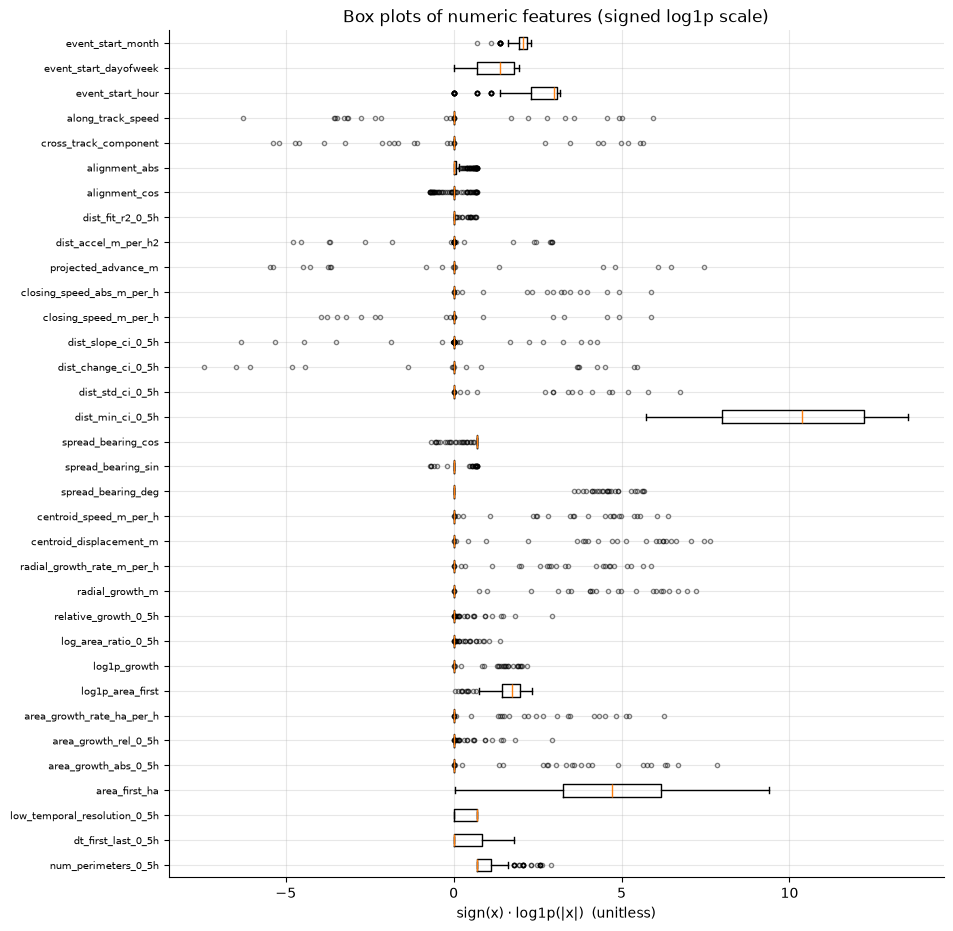

In [8]:
slog = np.sign(train[FEATURES]) * np.log1p(train[FEATURES].abs())
fig, ax = plt.subplots(figsize=(10, 11))
ax.boxplot([slog[c].values for c in FEATURES], orientation="horizontal", tick_labels=FEATURES, flierprops=dict(markersize=3, alpha=.5))
ax.set_title("Box plots of numeric features (signed log1p scale)")
ax.set_xlabel("sign(x) · log1p(|x|)  (unitless)"); ax.tick_params(axis="y", labelsize=7)
save(fig, "01_boxplots"); plt.show()

The 'outliers' are mostly the minority of fires that have several perimeters and real growth, so they are signal and not errors. **We do not remove them.** A median imputer, a scaler and tree models are robust to them.

## 6. Correlation heatmap
Pearson correlations among the features and the targets, drawn with `plt.imshow`. This shows redundant feature groups and the strongest target relationships.

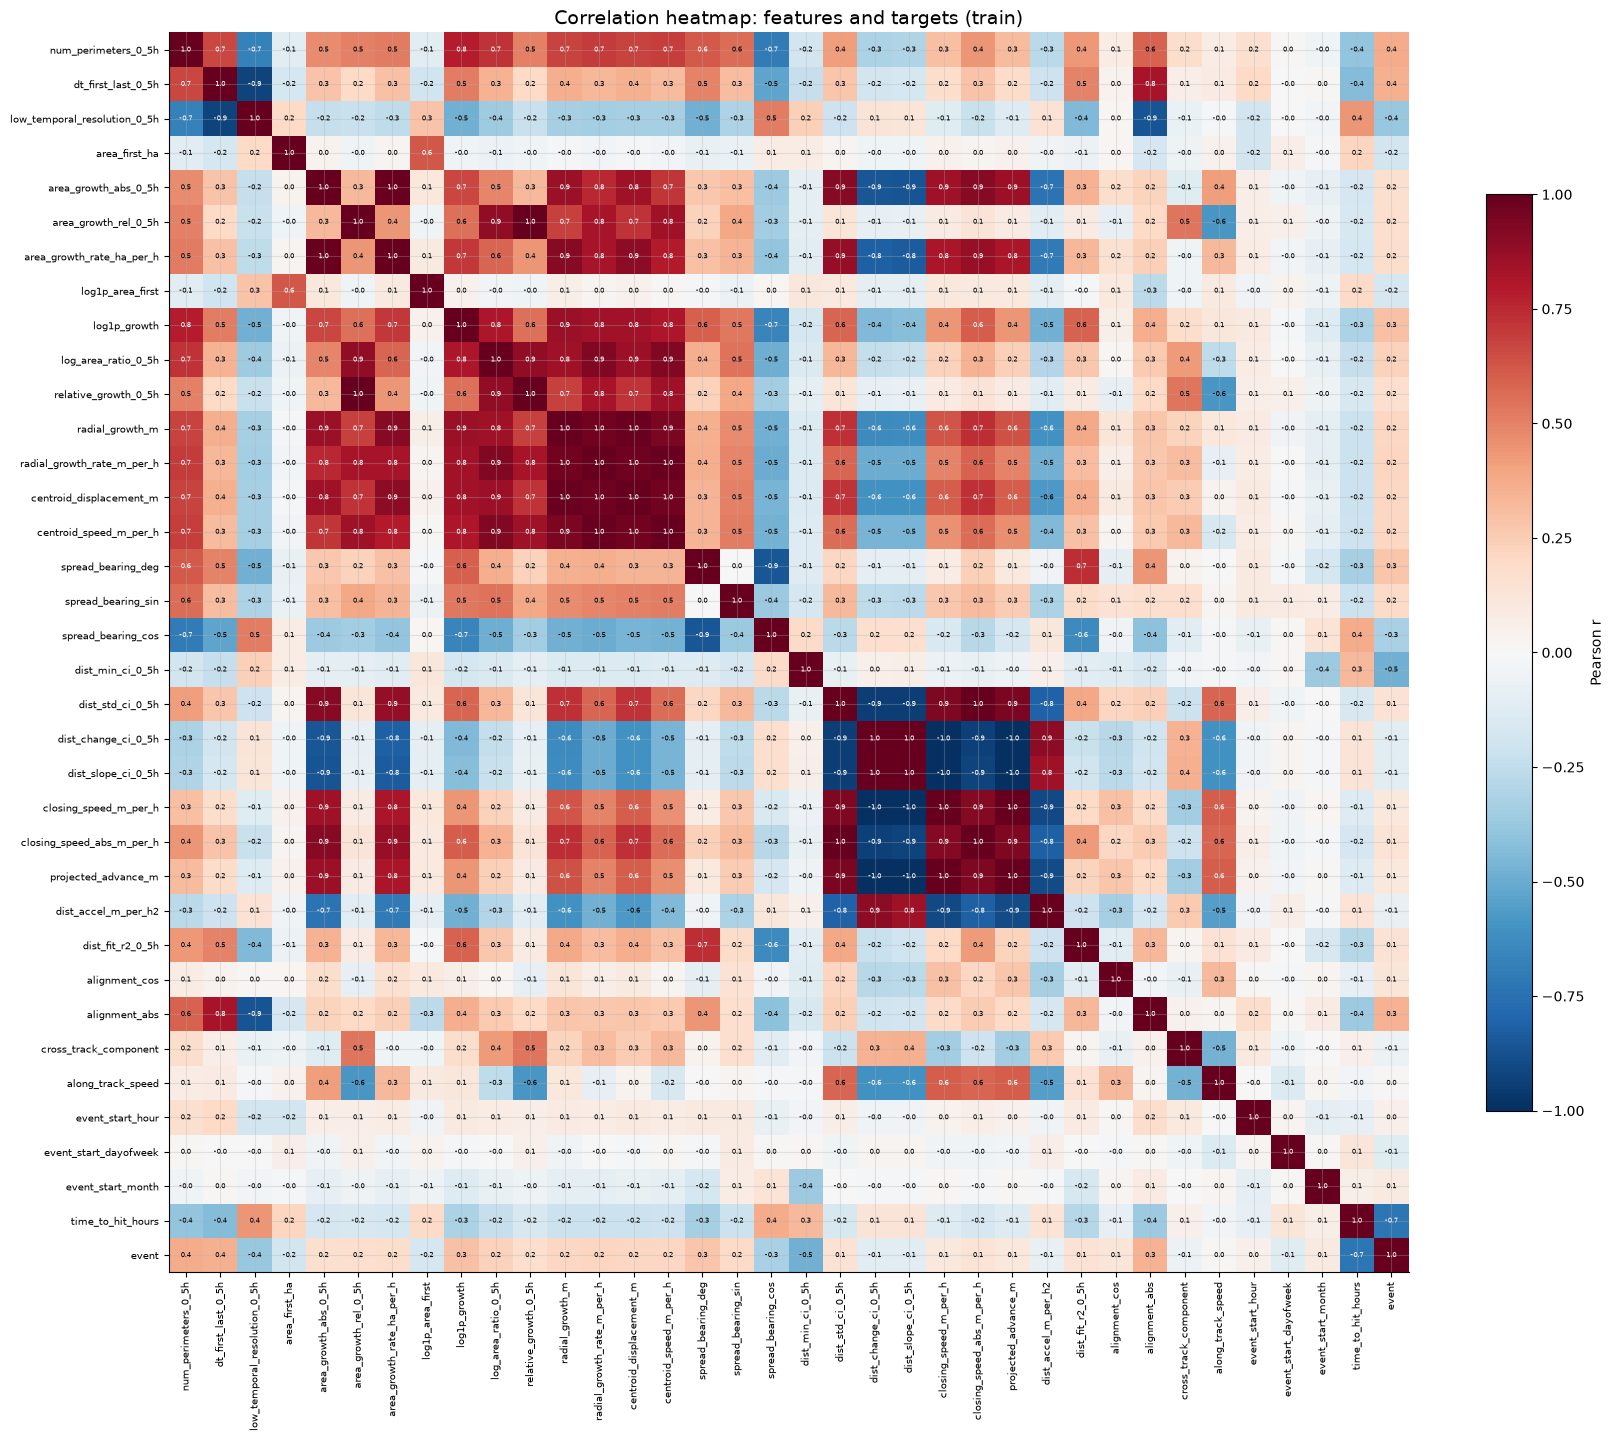

In [9]:
cols = FEATURES + [TIME_COL, EVENT_COL]
corr = train[cols].corr()
fig, ax = plt.subplots(figsize=(20, 17))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90, fontsize=7); ax.set_yticks(range(len(cols)), cols, fontsize=7)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=5, color="white" if abs(v) > .6 else "black")
fig.colorbar(im, ax=ax, shrink=.7, label="Pearson r")
ax.set_title("Correlation heatmap: features and targets (train)", fontsize=14)
save(fig, "01_correlation_heatmap"); plt.show()

There are clear **redundant groups**: `area_growth_rel_0_5h` is identical to `relative_growth_0_5h`, `closing_speed_abs` is almost identical to `projected_advance_m`, and radial growth tracks centroid speed. Regularised or tree models cope with this, so we keep all of them. Pearson r underplays `dist_min_ci_0_5h` because of its extreme skew (see section 7).

## 7. Features vs. target
The target is binary, so for each feature we compare the distribution for fires that **hit** vs. **never hit** (strip plots on a signed-log scale). The time-of-day, day and month columns are treated as categories, and we show the hit rate per value.

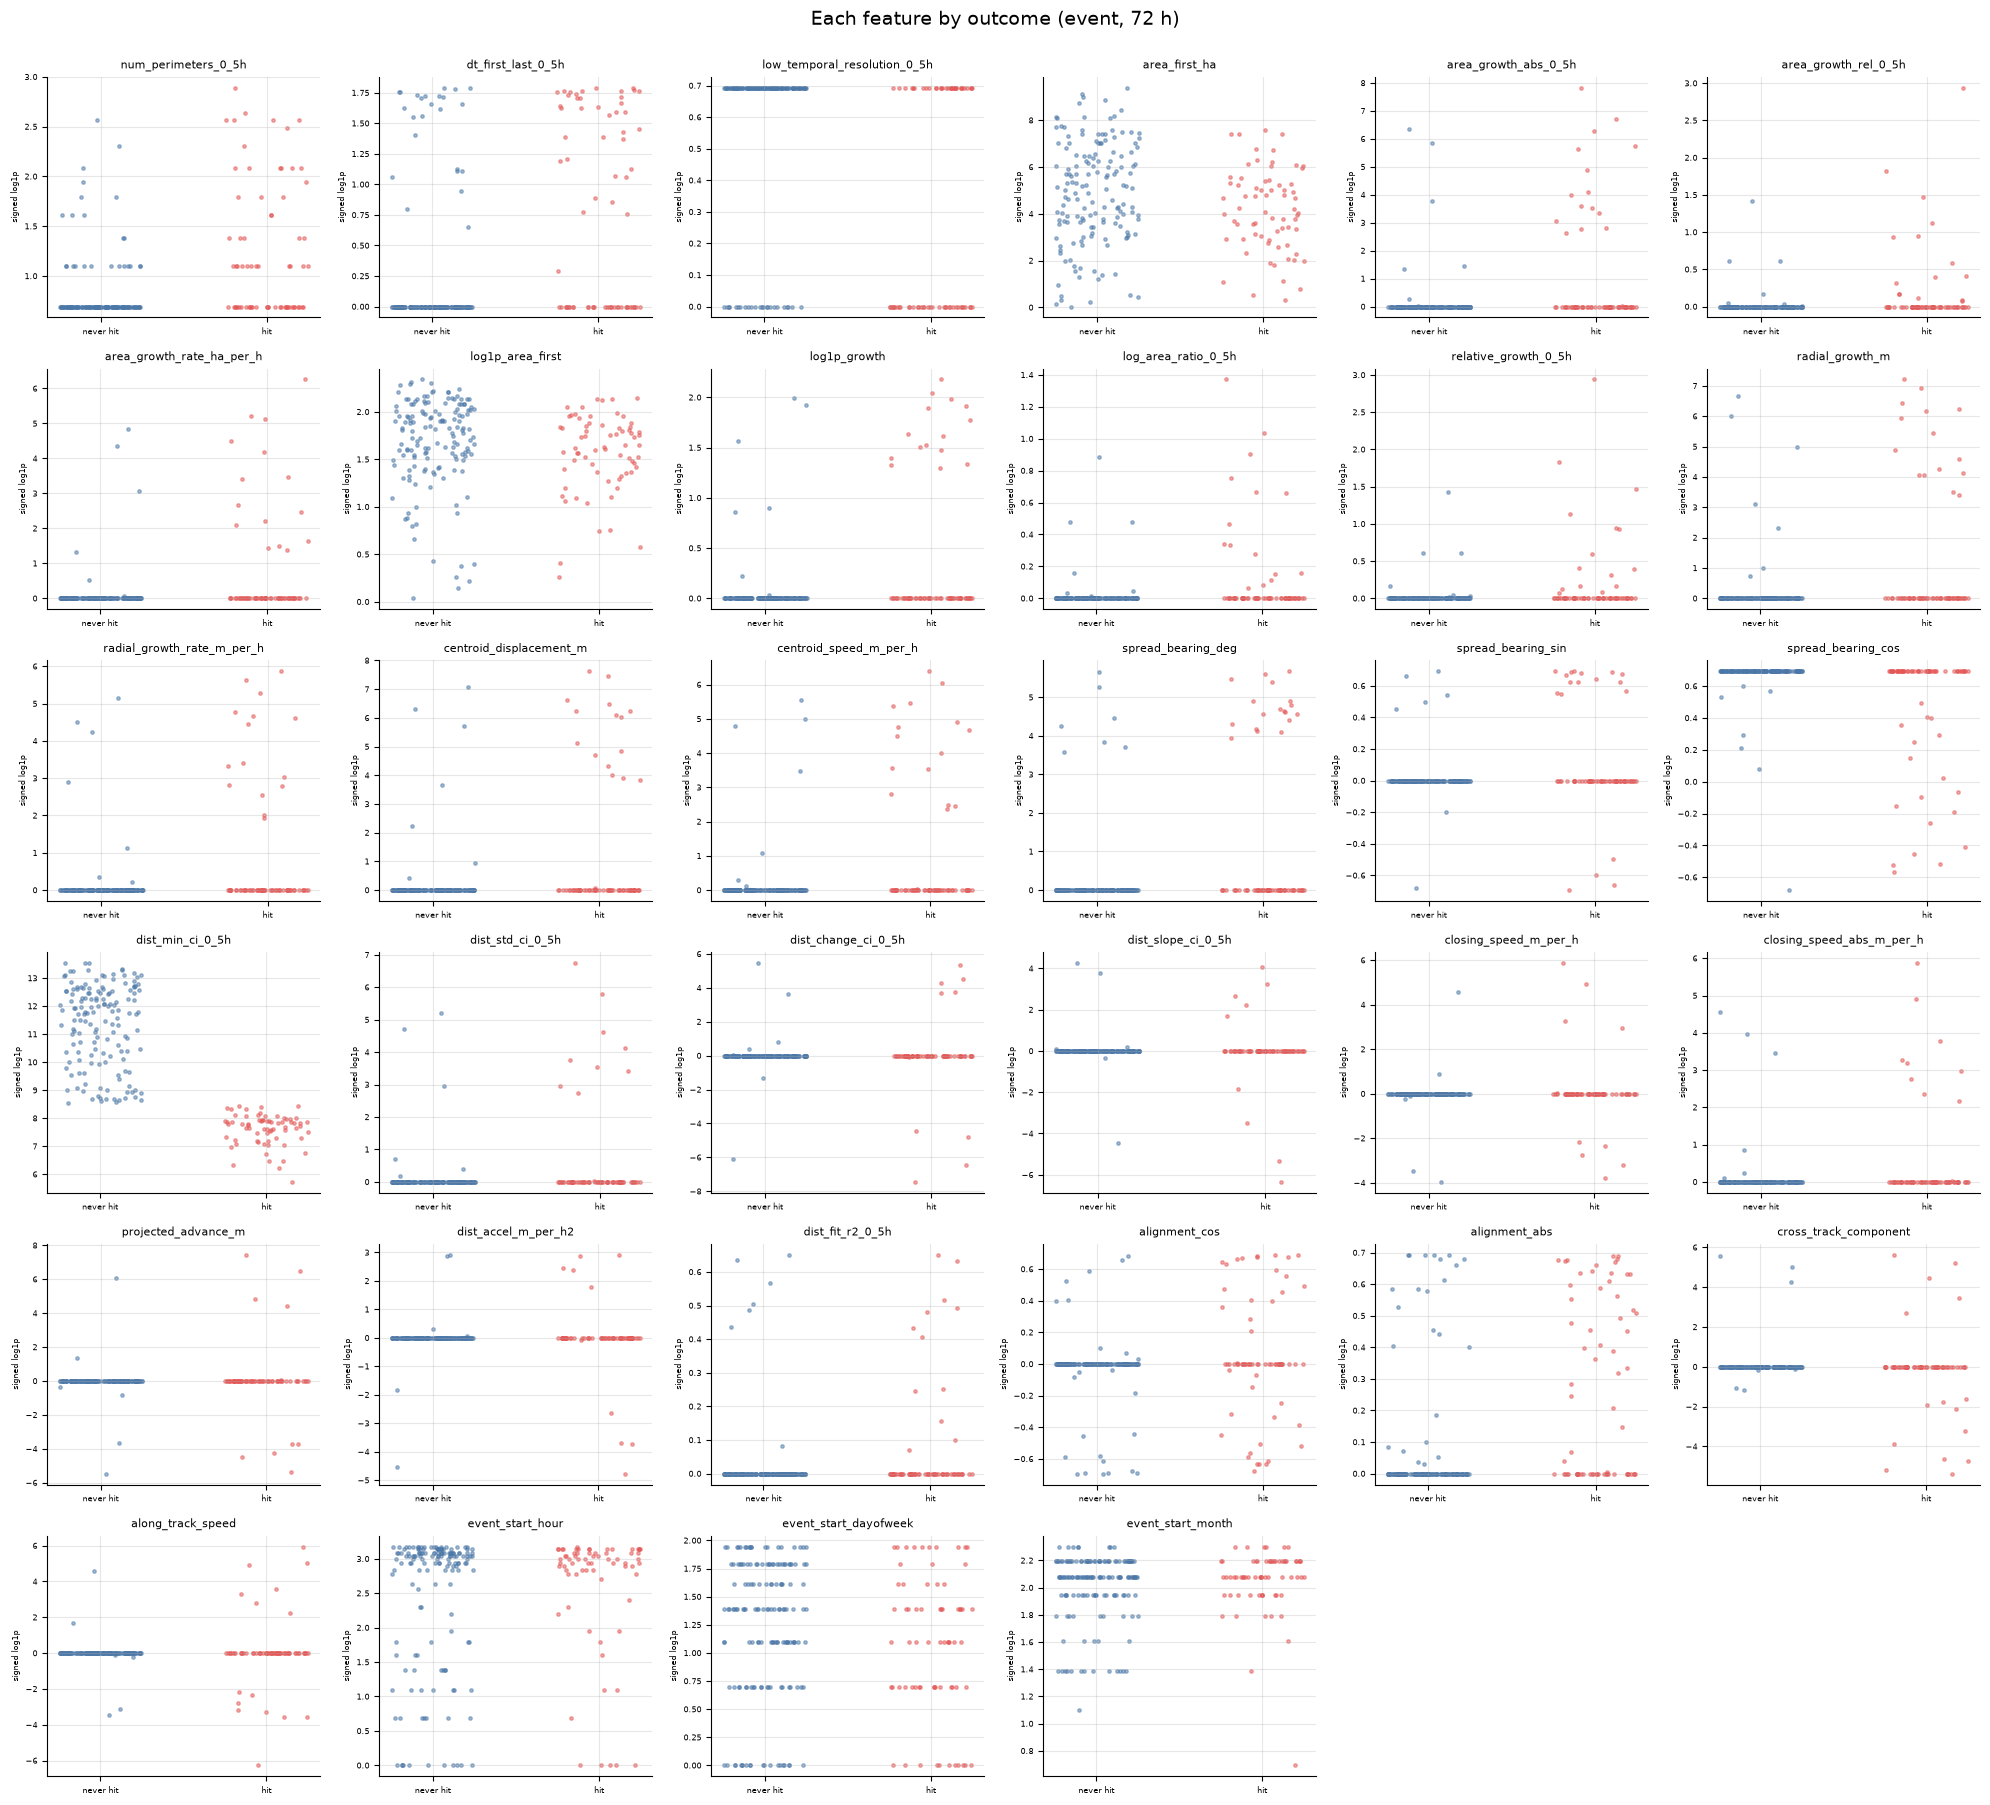

In [10]:
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3 * nrows))
rng = np.random.default_rng(42)
for ax, col in zip(axes.flat, FEATURES):
    for k, (lab, colr) in enumerate([(0, C_NEG), (1, C_POS)]):
        v = slog.loc[train[EVENT_COL] == lab, col]
        ax.scatter(k + rng.uniform(-.25, .25, len(v)), v, s=6, alpha=.5, color=colr)
    ax.set_xticks([0, 1], ["never hit", "hit"], fontsize=7); ax.set_title(col, fontsize=8)
    ax.set_ylabel("signed log1p", fontsize=6); ax.tick_params(labelsize=6)
for ax in axes.flat[n:]: ax.axis("off")
fig.suptitle("Each feature by outcome (event, 72 h)", y=1.0, fontsize=14)
fig.tight_layout(); save(fig, "01_feature_vs_target"); plt.show()

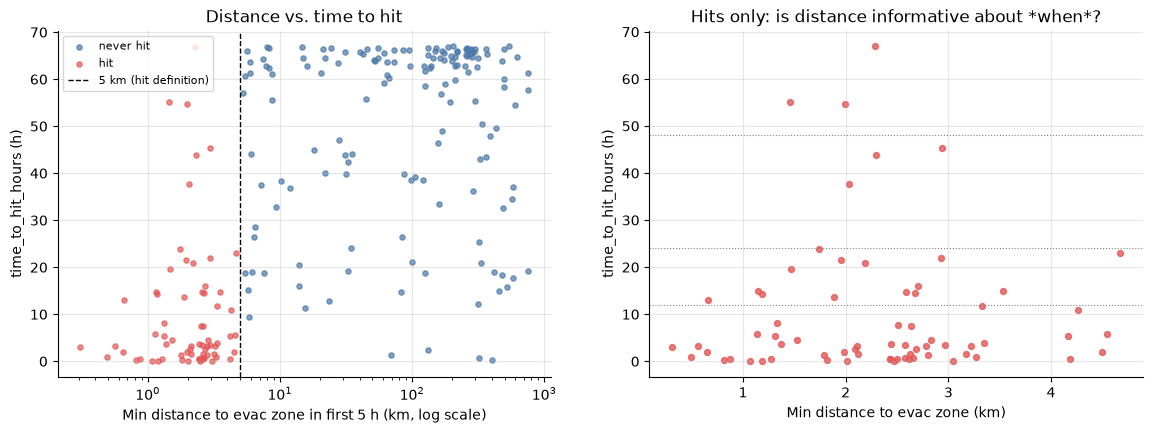

dist <=    3 km: n= 56  hit rate=1.00  hits beyond=13
dist <=    5 km: n= 69  hit rate=1.00  hits beyond=0
dist <=  5.2 km: n= 69  hit rate=1.00  hits beyond=0
dist <=   10 km: n= 91  hit rate=0.76  hits beyond=0
dist <=   50 km: n=119  hit rate=0.58  hits beyond=0

max dist among hits: 4674 m | min dist among non-hits: 5216 m
Spearman(dist, time) among hits: 0.08


In [11]:
# The decisive relationship: distance to the nearest evacuation zone
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for lab, colr, name in [(0, C_NEG, "never hit"), (1, C_POS, "hit")]:
    m = train[EVENT_COL] == lab
    axes[0].scatter(train.loc[m, "dist_min_ci_0_5h"] / 1000, train.loc[m, TIME_COL], s=14, alpha=.7, color=colr, label=name)
axes[0].axvline(5, color="k", ls="--", lw=1, label="5 km (hit definition)")
axes[0].set_xscale("log"); axes[0].set_xlabel("Min distance to evac zone in first 5 h (km, log scale)")
axes[0].set_ylabel("time_to_hit_hours (h)"); axes[0].set_title("Distance vs. time to hit"); axes[0].legend(fontsize=8)

hits = train[train[EVENT_COL] == 1]
axes[1].scatter(hits["dist_min_ci_0_5h"] / 1000, hits[TIME_COL], s=18, color=C_POS, alpha=.8)
for h in HORIZONS[:3]: axes[1].axhline(h, color="grey", ls=":", lw=.8)
axes[1].set_xlabel("Min distance to evac zone (km)"); axes[1].set_ylabel("time_to_hit_hours (h)")
axes[1].set_title("Hits only: is distance informative about *when*?")
save(fig, "01_distance_vs_target"); plt.show()

for th in [3, 5, 5.2, 10, 50]:
    m = train["dist_min_ci_0_5h"] <= th * 1000
    print(f"dist <= {th:>4} km: n={m.sum():3d}  hit rate={train.loc[m, EVENT_COL].mean():.2f}  hits beyond={train.loc[~m, EVENT_COL].sum()}")
print("\nmax dist among hits: %.0f m | min dist among non-hits: %.0f m" % (hits.dist_min_ci_0_5h.max(), train.loc[train[EVENT_COL]==0,'dist_min_ci_0_5h'].min()))
print("Spearman(dist, time) among hits: %.2f" % hits[["dist_min_ci_0_5h", TIME_COL]].corr(method="spearman").iloc[0,1])

⚠️ **Perfect separation at 72 h.** All 69 fires that hit were **within 4.7 km** of an evacuation zone during their first 5 hours. All 152 fires that never hit were **at least 5.2 km away**. One threshold on `dist_min_ci_0_5h` (about 5 km, the very distance that defines a 'hit') classifies the 72 h label **perfectly**. Fires that are already inside the radius may hit almost immediately (`time ≈ 0`) or only days later.

So *whether* a fire hits is trivial in this sample. *When* it hits (12 / 24 / 48 h) is the hard part, because among the hits distance is only weakly related to timing.

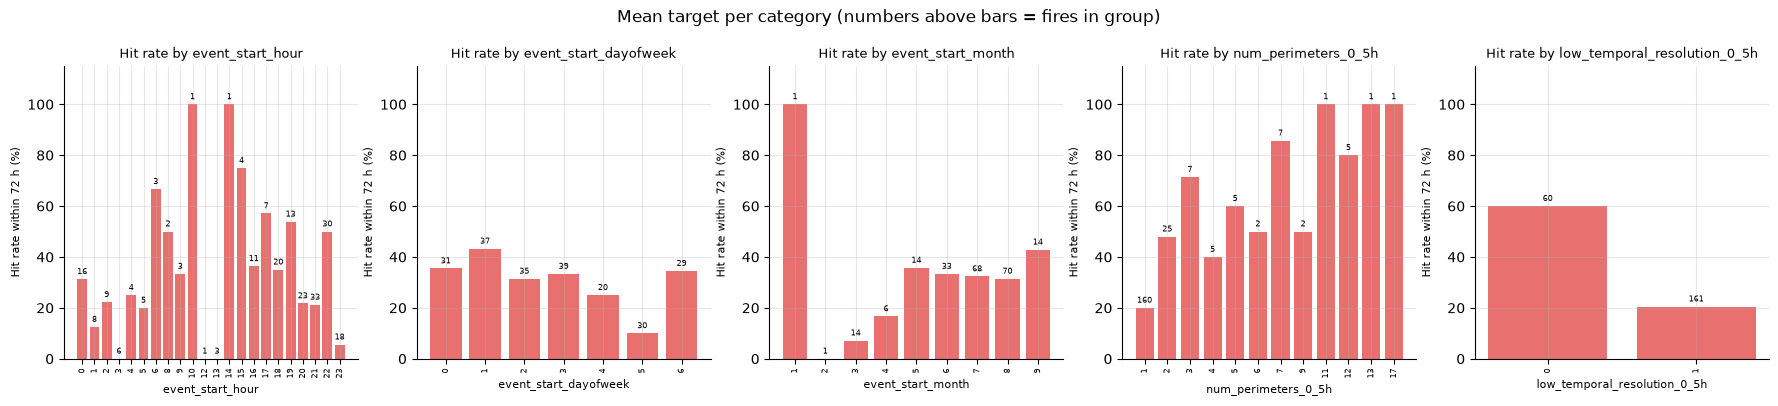

In [12]:
cat_cols = ["event_start_hour", "event_start_dayofweek", "event_start_month", "num_perimeters_0_5h", "low_temporal_resolution_0_5h"]
fig, axes = plt.subplots(1, len(cat_cols), figsize=(22, 3.8))
for ax, col in zip(axes, cat_cols):
    g = train.groupby(col)[EVENT_COL].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"] * 100, color=C_POS, alpha=.85)
    for x, (r, s) in enumerate(zip(g["mean"], g["size"])): ax.text(x, r * 100 + 2, str(s), ha="center", fontsize=6)
    ax.set_title(f"Hit rate by {col}", fontsize=9); ax.set_xlabel(col, fontsize=8); ax.set_ylabel("Hit rate within 72 h (%)", fontsize=8)
    ax.tick_params(axis="x", labelsize=6, rotation=90); ax.set_ylim(0, 115)
fig.suptitle("Mean target per category (numbers above bars = fires in group)", y=1.03)
save(fig, "01_category_hit_rates"); plt.show()

Fires with **several perimeters** (good temporal resolution) hit much more often (60% vs 20%). They are probably fires that were being actively mapped *because* they threatened something, so this is a selection effect and not physics. The hour, day and month groups are small and noisy, so we keep them as numeric or cyclic inputs and do not one-hot encode them.

## 8. Time trends
There is no date column, only the start month, day of week and hour. We plot fire counts and hit rate by month to look for seasonality.

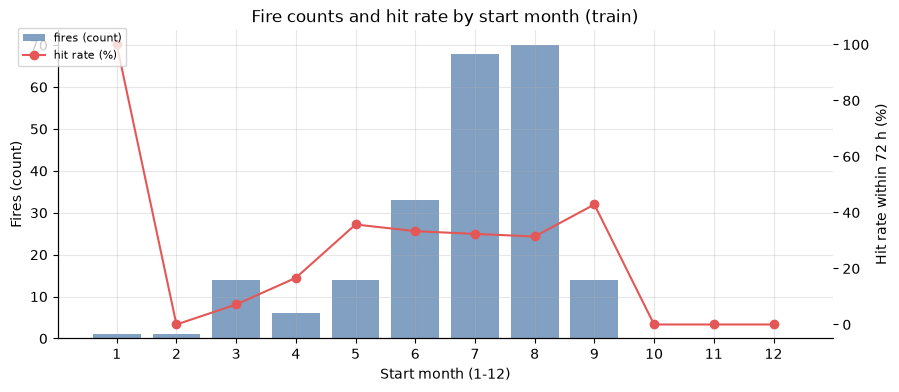

In [13]:
g = train.groupby("event_start_month")[EVENT_COL].agg(["size", "mean"]).reindex(range(1, 13), fill_value=0)
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(g.index, g["size"], color=C_NEG, alpha=.7, label="fires (count)")
ax1.set_xlabel("Start month (1-12)"); ax1.set_ylabel("Fires (count)"); ax1.set_xticks(range(1, 13))
ax2 = ax1.twinx(); ax2.plot(g.index, g["mean"] * 100, "o-", color=C_POS, label="hit rate (%)"); ax2.set_ylabel("Hit rate within 72 h (%)")
ax2.grid(False); ax1.set_title("Fire counts and hit rate by start month (train)")
fig.legend(loc="upper left", bbox_to_anchor=(.08, .9), fontsize=8)
save(fig, "01_time_trends_month"); plt.show()

Fires are concentrated in **June–August**, which is the fire season. The hit rate is fairly flat (about 30%) in the well-populated months. The spikes in Jan and Feb are single fires. Seasonality is weak once distance is known.

## 9. Geographic view
The dataset has **no latitude/longitude columns** (locations are anonymised), so a map is not possible. The nearest substitute is the direction the fire spreads (`spread_bearing_deg`) together with its distance, plotted below as a polar chart.

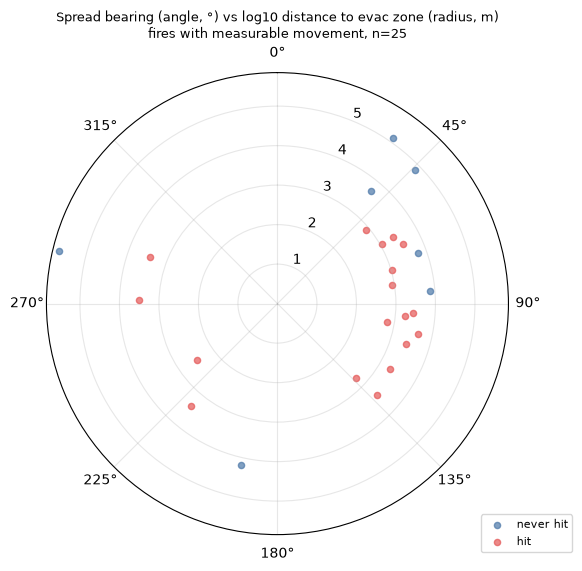

In [14]:
moving = train[train["centroid_displacement_m"] > 0]
fig = plt.figure(figsize=(6, 6)); ax = fig.add_subplot(projection="polar")
for lab, colr, name in [(0, C_NEG, "never hit"), (1, C_POS, "hit")]:
    m = moving[EVENT_COL] == lab
    ax.scatter(np.deg2rad(moving.loc[m, "spread_bearing_deg"]), np.log10(moving.loc[m, "dist_min_ci_0_5h"]), s=20, alpha=.7, color=colr, label=name)
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.set_title(f"Spread bearing (angle, °) vs log10 distance to evac zone (radius, m)\nfires with measurable movement, n={len(moving)}", fontsize=9)
ax.legend(loc="lower right", fontsize=8, bbox_to_anchor=(1.15, -0.05))
save(fig, "01_bearing_polar"); plt.show()

Only 25 fires show measurable movement. Hits sit at a smaller radius (closer), and spread direction does not separate the outcomes on its own.

## 10. Top features correlated with the target
We rank the features (raw and engineered) by |Spearman ρ| with `event` (did the fire ever hit) and with `hit_48h` (the most heavily weighted horizon, using evaluable rows only). Spearman is rank-based, so it is robust to the extreme skew.

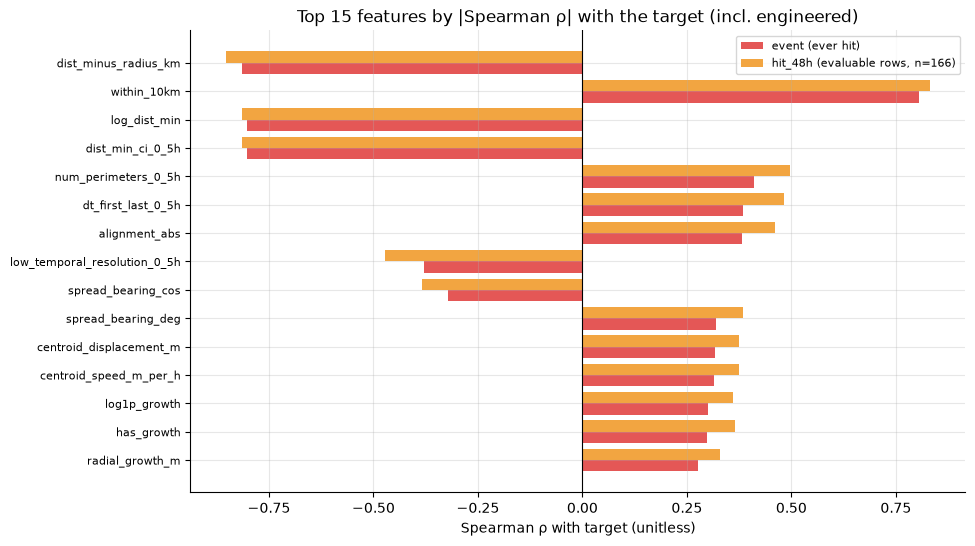

,event,hit_48h
dist_minus_radius_km,-0.815,-0.853
within_10km,0.805,0.832
dist_min_ci_0_5h,-0.803,-0.815
log_dist_min,-0.803,-0.815
num_perimeters_0_5h,0.411,0.496
dt_first_last_0_5h,0.384,0.482
alignment_abs,0.383,0.460
low_temporal_resolution_0_5h,-0.379,-0.473
spread_bearing_cos,-0.321,-0.384
spread_bearing_deg,0.320,0.384


In [15]:
eng = add_engineered_features(train[FEATURES])
rows = {"event": eng.apply(lambda s: s.corr(train[EVENT_COL], method="spearman"))}
m48 = train["hit_48h"].notna()
rows["hit_48h"] = eng[m48].apply(lambda s: s.corr(train.loc[m48, "hit_48h"], method="spearman"))
rank = pd.DataFrame(rows).dropna()
top = rank.reindex(rank["event"].abs().sort_values().index).tail(15)
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(top))
ax.barh(y - .2, top["event"], height=.4, color=C_POS, label="event (ever hit)")
ax.barh(y + .2, top["hit_48h"], height=.4, color="#F2A541", label=f"hit_48h (evaluable rows, n={m48.sum()})")
ax.set_yticks(y, top.index, fontsize=8); ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("Spearman ρ with target (unitless)"); ax.set_title("Top 15 features by |Spearman ρ| with the target (incl. engineered)")
ax.legend(fontsize=8)
save(fig, "01_top_correlations"); plt.show()
rank.reindex(rank["event"].abs().sort_values(ascending=False).index).head(10).round(3)

### Train vs. competition test: is the distribution comparable?

In [16]:
key = ["dist_min_ci_0_5h", "low_temporal_resolution_0_5h", "num_perimeters_0_5h", "area_first_ha"]
cmp = pd.DataFrame({"train_median": train_raw[key].median(), "test_median": test_raw[key].median(),
                    "train_mean": train_raw[key].mean(), "test_mean": test_raw[key].mean()})
print("share within 5 km  train: %.2f  test: %.2f" % ((train_raw.dist_min_ci_0_5h <= 5000).mean(), (test_raw.dist_min_ci_0_5h <= 5000).mean()))
cmp.round(2)

share within 5 km  train: 0.31  test: 0.29


,train_median,test_median,train_mean,test_mean
dist_min_ci_0_5h,31758.58,31003.47,124399.24,113200.65
low_temporal_resolution_0_5h,1.00,1.00,0.73,0.78
num_perimeters_0_5h,1.00,1.00,2.06,1.93
area_first_ha,110.15,84.59,619.13,891.30


## 11. Key Findings

| # | Finding | Consequence for modelling |
|---|---|---|
| 1 | **Small data:** 221 labelled fires (69 hits) and 34 numeric features, with no missing values, duplicates or id overlap with test. | Low-variance models, stratified **85/15** split + **5-fold CV** instead of a separate validation set. Metrics will have wide confidence intervals. |
| 2 | **Hits are perfectly separated from censored fires:** every hit had `dist_min_ci_0_5h` ≤ 4.7 km and every censored fire ≥ 5.2 km. The target is defined as 'within 5 km of an evac zone'. | Not leakage (the distance is measured in the first 5 h), but *whether* a fire hits is close to a lookup rule. The C-index (urgency ranking) and Brier@24h/48h depend on **timing**, which is the real modelling problem. |
| 3 | **Censoring is heavy and early:** censored fires were last seen at ≤ 67 h, so under the metric's rule 25 / 55 / 152 of them are excluded at 24 / 48 / 72 h, and **every evaluable fire at 72 h is a hit**. | Model selection uses the official **Hybrid score**. We compare training with censor-aware labels (rows dropped like in the metric) against treating censored fires as negatives. Hits happen early (median 3.5 h). One classifier per horizon, with probabilities **forced to be non-decreasing**. |
| 4 | About 89% of fires have zero measured growth or movement (one perimeter only). Non-zero values are extremely skewed. | Median imputer + `StandardScaler` per the template. Engineered `log_dist_min`, `dist_minus_radius_km`, `eta_hours`, `has_growth`. Tree ensembles are expected to do best. |
| 5 | Redundant feature groups (identical relative-growth columns, closing speed ≈ projected advance). | No manual pruning is needed for trees or regularised LR. Importance will be split across duplicates. |
| 6 | No categorical, date or geo columns. Hour, day and month are cyclic integers with small groups. | All features are numeric; add sin/cos encodings. The `OneHotEncoder` branch exists but is empty. |
| 7 | Test set looks similar to train (29% vs 31% within 5 km, similar low-resolution share). | The 72 h rule should transfer, and the model can be applied to `test.csv` for a submission. |
| 8 | Fires with several perimeters hit more often (60% vs 20%), which is likely monitoring/selection bias. | Note as a limitation: the model may learn 'being closely watched' as a risk signal. |